## future changes robustness

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [3]:
from scipy import stats

In [4]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [6]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [7]:
from functions import preproc_funcs as funcs

In [8]:
from functions import xr_lowess

#### load cmip6 data and data from access lens

In [9]:
ts_cmip_s5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp5.nc').ts
pr_cmip_s5 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/pr_ssp5.nc').pr*86400*30)

In [10]:
ts_access_s5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_ts.nc').ts
pr_access_s5 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_pr.nc').pr*86400*30)

In [11]:
ts_access_s2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp2_ts.nc').ts
pr_access_s2 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp2_pr.nc').pr*86400*30)

In [12]:
ts_canesm_s5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/CanESM5_ssp5_ts.nc').ts
pr_canesm_s5 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/CanESM5_ssp5_pr.nc').pr*86400*30)

In [13]:
ts_canesm_s2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/CanESM5_ssp2_ts.nc').ts
pr_canesm_s2 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/CanESM5_ssp2_pr.nc').pr*86400*30)

In [14]:
from dask.diagnostics import ProgressBar

In [15]:
weights_model = np.cos(np.deg2rad(ts_cmip_s5.lat))

nino34_cmip_s5 = funcs.detrend_rolling_window(ts_cmip_s5.sel(time = slice('1850', '2100')).sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), window_size=15).load()

In [16]:
# ts_access_anom = funcs.calc_anom(ts_access, ts_access.sel(time = slice('1960', '1990')))
nino34_access_s5 = funcs.detrend_rolling_window(ts_access_s5.sel(time = slice('1850', '2100')).sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), window_size=15).load()
nino34_access_s2 = funcs.detrend_rolling_window(ts_access_s2.sel(time = slice('1850', '2100')).sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), window_size=15).load()

In [17]:
nino34_canesm_s5 = funcs.detrend_rolling_window(ts_canesm_s5.sel(time = slice('1850', '2100')).sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), window_size=15).load()
nino34_canesm_s2 = funcs.detrend_rolling_window(ts_canesm_s2.sel(time = slice('1850', '2100')).sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), window_size=15).load()

In [18]:
import regionmask

In [19]:
land_mask_model = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_cmip_s5)
ar6_mask_model = regionmask.defined_regions.ar6.land.mask_3D(land_mask_model)

In [20]:
# pr_cmip_det_s5 = pr_cmip_s5 - pr_cmip_s5.rolling(time=15).mean('time')
# pr_cmip_std_s5 = pr_cmip_det_s5/pr_cmip_det_s5.std('time')

pr_access_det_s5 = funcs.detrend_rolling_window(pr_access_s5, window_size=15)
pr_access_std_s5 = pr_access_det_s5/pr_access_det_s5.std('time')

pr_access_det_s2 = funcs.detrend_rolling_window(pr_access_s2, window_size=15)
pr_access_std_s2 = pr_access_det_s2/pr_access_det_s2.std('time')

# pr_canesm_det = pr_canesm - pr_canesm.rolling(time=15).mean('time')
# pr_canesm_std = pr_canesm_det/pr_canesm_det.std('time')

In [21]:
# with ProgressBar():
#     ts_access_det_s5 = ts_access_s5 - ts_access_s5.rolling(time=15).mean('time')
#     ts_access_det_s2 = ts_access_s2 - ts_access_s2.rolling(time=15).mean('time')

In [22]:
pr_canesm_det_s5 = funcs.detrend_rolling_window(pr_canesm_s5, window_size=15)
pr_canesm_std_s5 = pr_canesm_det_s5/pr_canesm_det_s5.std('time')

pr_canesm_det_s2 = funcs.detrend_rolling_window(pr_canesm_s2, window_size=15)
pr_canesm_std_s2 = pr_canesm_det_s2/pr_canesm_det_s2.std('time')

In [26]:
# ts_canesm_det_s5 = ts_canesm_s5 - ts_canesm_s5.rolling(time=15).mean('time')
# ts_canesm_det_s2 = ts_canesm_s2 - ts_canesm_s2.rolling(time=15).mean('time')

In [25]:
pr_access_std_s5['model'] = nino34_access_s5['model']
pr_access_std_s2['model'] = nino34_access_s2['model']

In [23]:
pr_canesm_std_s5['model'] = nino34_canesm_s5['model']
pr_canesm_std_s2['model'] = nino34_canesm_s2['model']

In [26]:
regr_access_hist = funcs.get_regr(nino34_access_s5.sel(time = slice('1900', '2014')), pr_access_std_s5.sel(time = slice('1900', '2014')), dim='time')

In [58]:
regr_access_eoc_s5 = funcs.get_regr(nino34_access_s5.sel(time = slice('2050', '2100')), pr_access_std_s5.sel(time = slice('2050', '2100')), dim='time')

In [59]:
regr_access_eoc_s2 = funcs.get_regr(nino34_access_s2.sel(time = slice('2050', '2100')), pr_access_std_s2.sel(time = slice('2050', '2100')), dim='time')

In [35]:
# ts_regr_access_hist = funcs.get_regr(nino34_access_s5.sel(time = slice('1900', '2014')), ts_access_det_s5.sel(time = slice('1900', '2014')), dim='time')

In [36]:
# ts_regr_access_eoc_s5 = funcs.get_regr(nino34_access_s5.sel(time = slice('2070', '2100')), ts_access_det_s5.sel(time = slice('2070', '2100')), dim='time')

In [37]:
# ts_regr_access_eoc_s2 = funcs.get_regr(nino34_access_s2.sel(time = slice('2070', '2100')), ts_access_det_s2.sel(time = slice('2070', '2100')), dim='time')

In [60]:
regr_canesm_hist = funcs.get_regr(nino34_canesm_s5.sel(time = slice('1900', '2014')), pr_canesm_std_s5.sel(time = slice('1900', '2014')), dim='time')

In [61]:
regr_canesm_eoc_s5 = funcs.get_regr(nino34_canesm_s5.sel(time = slice('2050', '2100')), pr_canesm_std_s5.sel(time = slice('2050', '2100')), dim='time')

In [62]:
regr_canesm_eoc_s2 = funcs.get_regr(nino34_canesm_s2.sel(time = slice('2050', '2100')), pr_canesm_std_s2.sel(time = slice('2050', '2100')), dim='time')

In [41]:
# ts_regr_canesm_hist = funcs.get_regr(nino34_canesm_s5.sel(time = slice('1900', '2014')), ts_canesm_det_s5.sel(time = slice('1900', '2014')), dim='time')

In [42]:
# ts_regr_canesm_eoc_s5 = funcs.get_regr(nino34_canesm_s5.sel(time = slice('2070', '2100')), ts_canesm_det_s5.sel(time = slice('2070', '2100')), dim='time')

In [43]:
# ts_regr_canesm_eoc_s2 = funcs.get_regr(nino34_canesm_s2.sel(time = slice('2070', '2100')), ts_canesm_det_s2.sel(time = slice('2070', '2100')), dim='time')

In [32]:
def sign_test1d(past, future):
    count = 0
    for i in range(len(past)):
        if np.mean(future) > np.mean(past):
            if future[i] > past[i]:
                count += 1
        else:
            if future[i] < past[i]:
                count += 1

    return count/len(past)



def sign_test3d(past_da, future_da, dim='model'):
    return xr.apply_ufunc(sign_test1d, past_da, future_da, input_core_dims=[[dim], [dim]], vectorize=True, dask="parallelized")

In [33]:
# making 3d version of mann whitney u test
def ks1d(dist1, dist2):
    return float(stats.ks_2samp(dist1, dist2).pvalue)


def ks3d(da1, da2, dim):
    return xr.apply_ufunc(ks1d, da1, da2, input_core_dims=[[dim], [dim]], exclude_dims={dim, dim}, vectorize=True, dask='parallelized')

In [63]:
sign_access_s5 = sign_test3d(regr_access_hist, regr_access_eoc_s5)

In [64]:
# ts_sign_access_s5 = sign_test3d(ts_regr_access_hist, ts_regr_access_eoc_s5)

In [65]:
sign_access_s2 = sign_test3d(regr_access_hist, regr_access_eoc_s2)

In [38]:
# ts_sign_access_s2 = sign_test3d(ts_regr_access_hist, ts_regr_access_eoc_s2)

In [66]:
import seaborn as sns

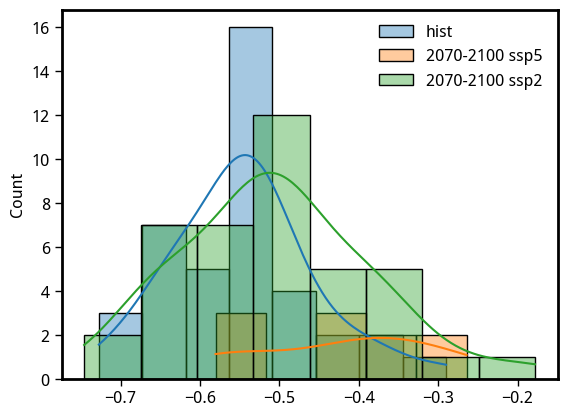

In [67]:
sns.histplot(regr_access_hist.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon')), kde=True, alpha=0.4, label='hist')
sns.histplot(regr_access_eoc_s5.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon')), kde=True, alpha=0.4, label='2070-2100 ssp5')
sns.histplot(regr_access_eoc_s2.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon')), kde=True, alpha=0.4, label='2070-2100 ssp2')
plt.legend(frameon=False)

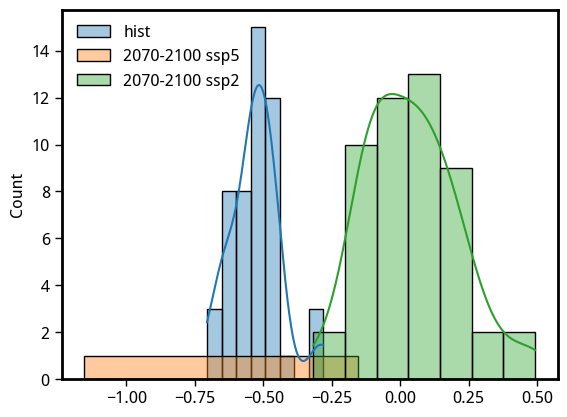

In [74]:
sns.histplot(regr_canesm_hist.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon')), kde=True, alpha=0.4, label='hist')
sns.histplot(regr_canesm_eoc_s5.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon')), kde=True, alpha=0.4, label='2070-2100 ssp5')
sns.histplot(regr_canesm_eoc_s2.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon')), kde=True, alpha=0.4, label='2070-2100 ssp2')
plt.legend(frameon=False)

{'whiskers': [<matplotlib.lines.Line2D at 0x7f810546a8e0>,
 'caps': [<matplotlib.lines.Line2D at 0x7f810546ae80>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f810546a610>,
 'medians': [<matplotlib.lines.Line2D at 0x7f81053fb460>,
 'fliers': [<matplotlib.lines.Line2D at 0x7f81053fb730>,
 'means': []}

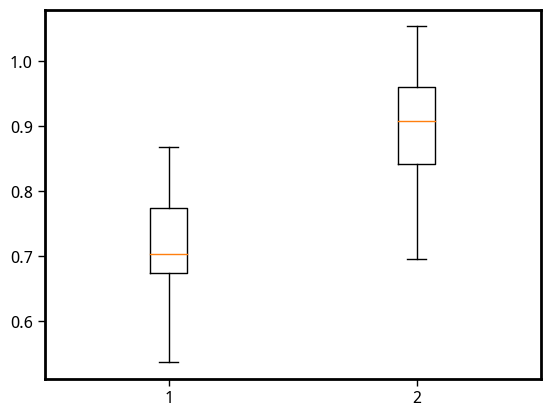

In [75]:
plt.boxplot([nino34_access_s2.sel(time = slice('2050', '2100')).std('time'),
             nino34_access_s5.sel(time = slice('2050', '2100')).std('time'),
            ])

{'whiskers': [<matplotlib.lines.Line2D at 0x7f81053dc9a0>,
 'caps': [<matplotlib.lines.Line2D at 0x7f81053dcf40>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f81053dc610>,
 'medians': [<matplotlib.lines.Line2D at 0x7f81053ec520>,
 'fliers': [<matplotlib.lines.Line2D at 0x7f81053ec7f0>,
 'means': []}

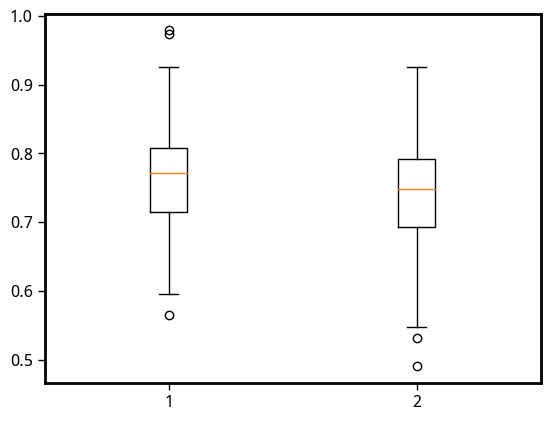

In [76]:
plt.boxplot([nino34_canesm_s2.sel(time = slice('2050', '2100')).std('time'),
             nino34_canesm_s5.sel(time = slice('2050', '2100')).std('time'),
            ])

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

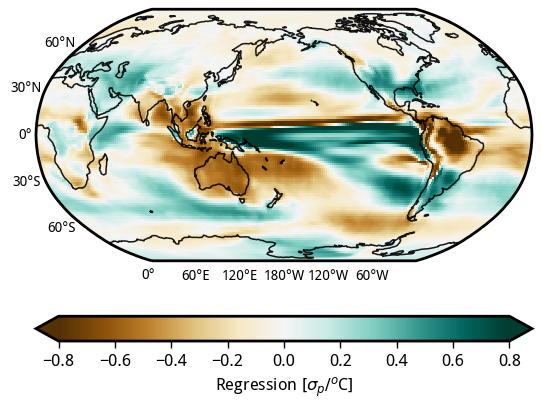

In [77]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(regr_access_hist).mean('model').plot(cmap='BrBG', vmin=-0.8, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
# xx, yy = np.meshgrid(regr_access_hist.lon, regr_access_hist.lat)
# zz = np.ma.masked_less_equal(pval_access_hist, 0.8)
# ax.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

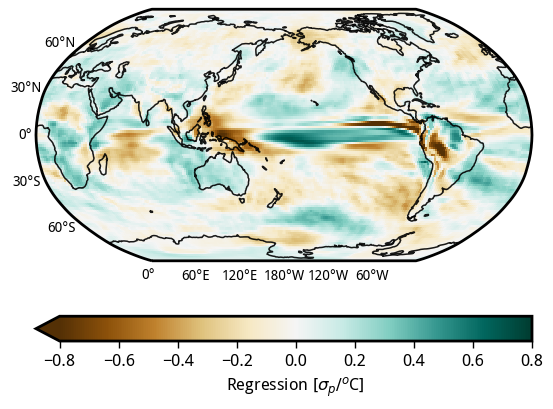

In [78]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(regr_access_eoc_s5 - regr_access_hist).mean('model').plot(cmap='BrBG', vmin=-0.8, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(regr_access_hist.lon, regr_access_hist.lat)
zz = np.ma.masked_less_equal(sign_access_s5, 0.8)
ax.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

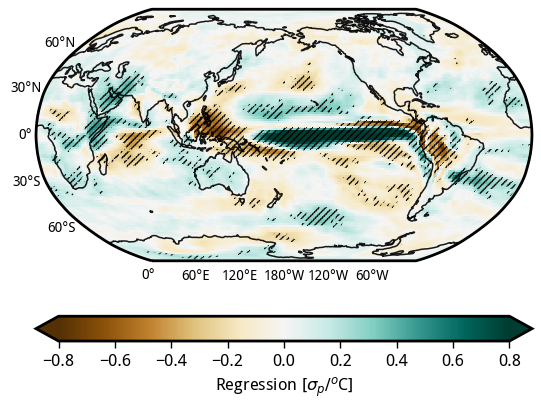

In [79]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(regr_access_eoc_s2 - regr_access_hist).mean('model').plot(cmap='BrBG', vmin=-0.8, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(regr_access_hist.lon, regr_access_hist.lat)
zz = np.ma.masked_less_equal(sign_access_s2, 0.8)
ax.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)

In [80]:
sign_canesm_s5 = sign_test3d(regr_canesm_hist, regr_canesm_eoc_s5)

In [81]:
sign_canesm_s2 = sign_test3d(regr_canesm_hist, regr_canesm_eoc_s2)

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

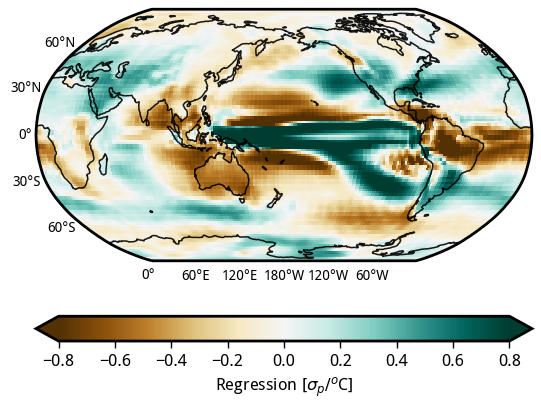

In [82]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(regr_canesm_hist).mean('model').plot(cmap='BrBG', vmin=-0.8, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
# xx, yy = np.meshgrid(regr_canesm_hist.lon, regr_canesm_hist.lat)
# zz = np.ma.masked_less_equal(pval_canesm_hist, 0.8)
# ax.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

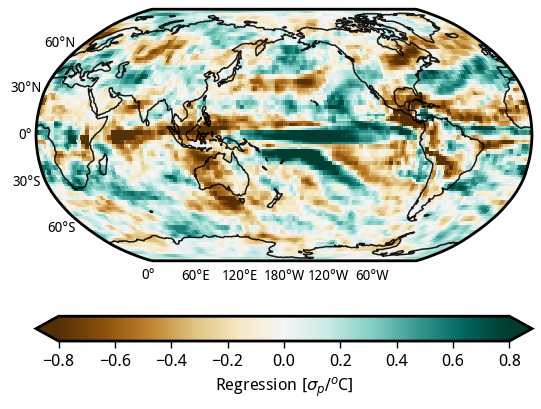

In [83]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(regr_canesm_eoc_s5 - regr_canesm_hist).mean('model').plot(cmap='BrBG', vmin=-0.8, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(regr_canesm_hist.lon, regr_canesm_hist.lat)
zz = np.ma.masked_less_equal(sign_canesm_s5, 0.8)
ax.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

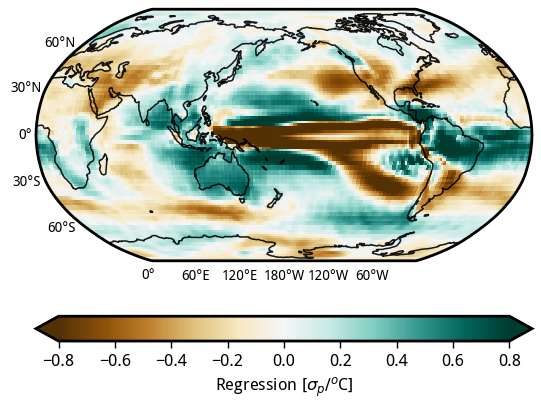

In [84]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(regr_canesm_eoc_s2 - regr_canesm_hist).mean('model').plot(cmap='BrBG', vmin=-0.8, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
# xx, yy = np.meshgrid(regr_canesm_hist.lon, regr_canesm_hist.lat)
# zz = np.ma.masked_less_equal(sign_canesm_s2, 0.8)
# ax.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)